In [12]:
import os, glob, re

import numpy as np
import scipy.io as sio
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader

# Pick the best available device.
# This laptop has an Intel Arc GPU -> PyTorch exposes it as "xpu" (not "cuda", which is NVIDIA only).
if torch.cuda.is_available():
    device = torch.device("cuda")
elif hasattr(torch, "xpu") and torch.xpu.is_available():
    device = torch.device("xpu")
else:
    device = torch.device("cpu")

print("PyTorch:", torch.__version__)
print("Device :", device)
if device.type == "xpu":
    print("GPU    :", torch.xpu.get_device_name(0))

PyTorch: 2.14.1+cu130
Device : cuda


In [18]:
from datasets import load_dataset

ds = load_dataset("Bingsu/Human_Action_Recognition")

ds



/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


README.md:   0%|          | 0.00/4.70k [00:00<?, ?B/s]

dataset_infos.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  229MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 98.1MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/12600 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5400 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'labels'],
        num_rows: 12600
    })
    test: Dataset({
        features: ['image', 'labels'],
        num_rows: 5400
    })
})

In [20]:
# ---- Train / Validation / Test split ----
# The dataset only ships "train" and "test". We carve a validation set out of train.
# Note: on this dataset the "test" labels may not be usable (Kaggle competition origin).
# If all test labels are the same class, we build a labelled test set from train instead.
from collections import Counter

SEED = 42
test_label_counts = Counter(ds["test"]["labels"])

if len(test_label_counts) > 1:
    # Test labels are real -> keep the official test split, take 15% of train for validation
    split = ds["train"].train_test_split(test_size=0.15, stratify_by_column="labels", seed=SEED)
    train_ds, val_ds = split["train"], split["test"]
    test_ds = ds["test"]
    print("Using the official test split.")
else:
    # Test labels unusable -> 70% train / 15% val / 15% test, all from the labelled train split
    split1 = ds["train"].train_test_split(test_size=0.30, stratify_by_column="labels", seed=SEED)
    split2 = split1["test"].train_test_split(test_size=0.50, stratify_by_column="labels", seed=SEED)
    train_ds, val_ds, test_ds = split1["train"], split2["train"], split2["test"]
    print("Official test labels are all the same class -> test set built from train.")

print(f"Train      : {len(train_ds)} images")
print(f"Validation : {len(val_ds)} images")
print(f"Test       : {len(test_ds)} images")

Official test labels are all the same class -> test set built from train.
Train      : 8820 images
Validation : 1890 images
Test       : 1890 images


In [21]:
# ---- Preprocessing + DataLoaders ----
# Images in this dataset have different sizes, so we resize them all to IMG_SIZE x IMG_SIZE.
from torchvision import transforms

IMG_SIZE   = 128
BATCH_SIZE = 32

train_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),          # light augmentation, train only
    transforms.ToTensor(),                      # -> (C, H, W), values in [0, 1]
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])
eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

def make_transform(tf):
    def apply(batch):
        batch["pixel_values"] = [tf(img.convert("RGB")) for img in batch["image"]]
        return batch
    return apply

def collate(batch):
    x = torch.stack([b["pixel_values"] for b in batch])
    y = torch.tensor([b["labels"] for b in batch])
    return x, y

train_ds.set_transform(make_transform(train_tf))
val_ds.set_transform(make_transform(eval_tf))
test_ds.set_transform(make_transform(eval_tf))

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  collate_fn=collate, num_workers=2)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate, num_workers=2)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate, num_workers=2)

print(f"Batches -> train: {len(train_loader)}, val: {len(val_loader)}, test: {len(test_loader)}")

Batches -> train: 276, val: 60, test: 60


In [22]:
# ---- Dataset information: classes, image size, channels, batch ----
class_names = ds["train"].features["labels"].names
num_classes = len(class_names)

print(f"Number of classes: {num_classes}\n")
# with_format(None) gives a view without the image transform, so reading labels is fast
train_counts = Counter(train_ds.with_format(None)["labels"])
val_counts   = Counter(val_ds.with_format(None)["labels"])
test_counts  = Counter(test_ds.with_format(None)["labels"])
print(f"{'id':>3}  {'class':<20}{'train':>7}{'val':>7}{'test':>7}")
for i, name in enumerate(class_names):
    print(f"{i:>3}  {name:<20}{train_counts[i]:>7}{val_counts[i]:>7}{test_counts[i]:>7}")

# Original (raw) image sizes vary -> look at a few
raw_sizes = Counter(ds["train"][i]["image"].size for i in range(200))
print("\nMost common raw sizes (W x H) in first 200 images:", raw_sizes.most_common(3))

# One batch after preprocessing
images, labels = next(iter(train_loader))
B, C, H, W = images.shape
print(f"\nBatch tensor shape : {tuple(images.shape)}  -> (batch, channels, height, width)")
print(f"Batch size         : {B}")
print(f"Channels           : {C}  (RGB)")
print(f"Image dimension    : {H} x {W} pixels")
print(f"Labels shape       : {tuple(labels.shape)}")

Number of classes: 15

 id  class                 train    val   test
  0  calling                 588    126    126
  1  clapping                588    126    126
  2  cycling                 588    126    126
  3  dancing                 588    126    126
  4  drinking                588    126    126
  5  eating                  588    126    126
  6  fighting                588    126    126
  7  hugging                 588    126    126
  8  laughing                588    126    126
  9  listening_to_music      588    126    126
 10  running                 588    126    126
 11  sitting                 588    126    126
 12  sleeping                588    126    126
 13  texting                 588    126    126
 14  using_laptop            588    126    126

Most common raw sizes (W x H) in first 200 images: [((275, 183), 51), ((183, 275), 12), ((300, 168), 11)]

Batch tensor shape : (32, 3, 128, 128)  -> (batch, channels, height, width)
Batch size         : 32
Channels         

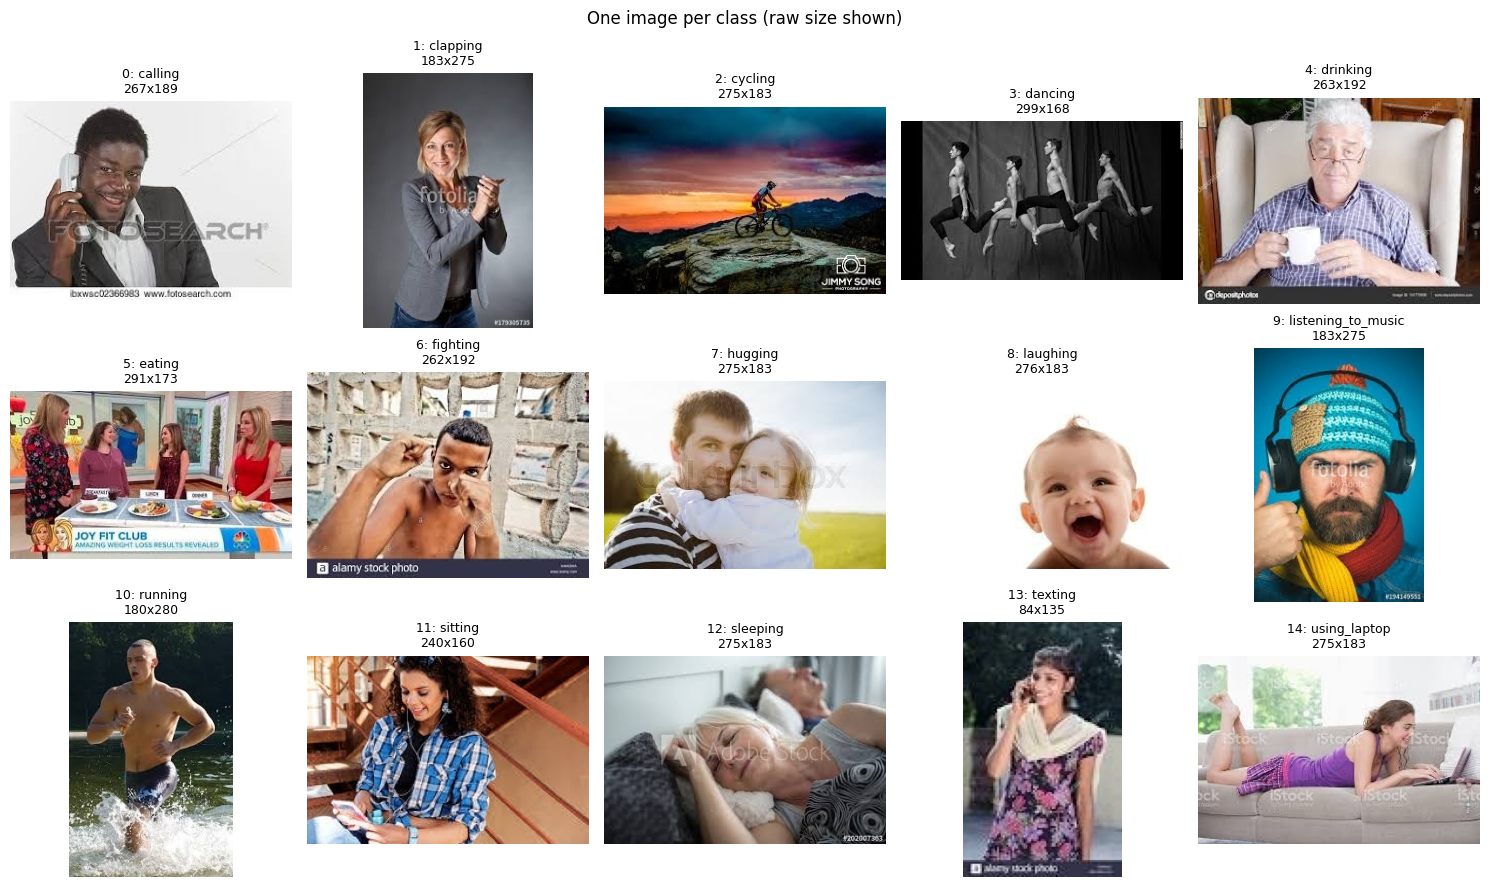

In [23]:
# ---- Show one example image per class ----
raw_labels = np.array(ds["train"]["labels"])
cols = 5
rows = int(np.ceil(num_classes / cols))
fig, axes = plt.subplots(rows, cols, figsize=(3 * cols, 3 * rows))

for i, ax in enumerate(axes.flat):
    ax.axis("off")
    if i >= num_classes:
        continue
    idx = int(np.where(raw_labels == i)[0][0])
    img = ds["train"][idx]["image"]
    ax.imshow(img)
    ax.set_title(f"{i}: {class_names[i]}\n{img.size[0]}x{img.size[1]}", fontsize=9)

plt.suptitle("One image per class (raw size shown)")
plt.tight_layout()
plt.show()